# BÁO CÁO MILESTONE 2 - HIERARCHY CONSTRUCTION
**Thành viên thực hiện:** Tân  
**Nhiệm vụ:** Xây dựng cây phân cấp (Hierarchy Construction) cho các ấn phẩm LaTeX theo quy chuẩn Parsing Notes (Milestone 2)  
**Nhóm:** Nhóm 11 - Nhập môn Khoa học Dữ liệu

---

## 1. Luồng Hoạt Động & Luồng Dữ Liệu (Data & Execution Workflow)

Trong quy trình xử lý 4 bước của Nhóm 11 (**Hoàng $\rightarrow$ Tân $\rightarrow$ Khoa $\rightarrow$ Kiệt**), phần **Hierarchy Construction** đóng vai trò cầu nối chuyển đổi văn bản LaTeX phẳng từ thư mục `elements/` thành cấu trúc cây phân cấp (Hierarchy Tree) cho từng version của mỗi bài báo:

```text
[Bước 1 - Hoàng: Multi-file Gathering]
   └── <pub_dir>/elements/full_inlined_vX.tex (Mã nguồn LaTeX đã gộp theo luồng biên dịch)
          │
          ▼
[Bước 2 - Tân: Hierarchy Construction (src/parser/hierarchy_builder.py & src/run_hierarchy.py)]
   ├── 1. Tách thân bài (\begin{document}...\end{document}) & Loại bỏ frontmatter (\title, \author...)
   ├── 2. Loại trừ References khỏi cây (Exclusions) nhưng LƯU RIÊNG vào elements/raw_references.json cho Khoa
   ├── 3. Bảo toàn Acknowledgements & Appendices (Inclusions: \section*, \begin{acknowledgments}, \appendix)
   ├── 4. Nhận diện khối cấu trúc & Tách nút lá an toàn (split_sentences_safe với cơ chế Masking/Unmasking)
   │      -> Giữ nguyên Raw LaTeX Content ở nút lá để Khoa thực hiện Data Standardization
   ├── 5. Dựng cây phân cấp bằng Ngăn xếp động (Dynamic Heading Stack) + Đệ quy danh sách (itemize/item)
   └── 6. Ghi nhận các Version rỗng (Empty Records) nếu version không có mã nguồn .tex
          │
          ▼
[Đầu ra của Tân trong mỗi <pub_dir>/]
   ├── <pub_dir>/vX/hierarchy_tree.json           (Cây phân cấp lồng nhau của từng version v1, v2...)
   ├── <pub_dir>/elements/hierarchy_tree_vX.json  (Bản lưu cây phân cấp từng version trong elements/)
   ├── <pub_dir>/elements/elements_vX.json        (Danh sách elements thô của từng version)
   ├── <pub_dir>/elements/hierarchy_vX.json       (Danh sách cạnh cha-con của từng version)
   ├── <pub_dir>/elements/raw_references.json     (Khối \bibitem & \bibliography lưu riêng cho Khoa)
   └── <pub_dir>/elements/elements.json & hierarchy.json (Bảng chuẩn schema Milestone 2)
```


## 2. Các Thư Viện & Công Cụ Sử Dụng

| Thư viện / Module | Chức năng trong phần Hierarchy Construction |
| :--- | :--- |
| `re` (Regular Expressions) | Nhận diện các lệnh phân cấp (`\chapter`, `\section*`, `\subsection`...), tách khối `equation`, `figure`, `table` và thực hiện cơ chế **Masking / Unmasking** bảo vệ toán, lệnh LaTeX, URL, số thập phân và từ viết tắt khi tách câu. |
| `pathlib.Path` | Quản lý đường dẫn đa nền tảng, duyệt qua các thư mục publication và từng version (`v1`, `v2`, ...) trong `./source` / `src/sourcesArxiv`. |
| `json` | Xuất cấu trúc cây phân cấp (`hierarchy_tree.json`), bảng phần tử (`elements.json`), bảng cạnh (`hierarchy.json`) và dữ liệu tham khảo thô (`raw_references.json`). |
| `pandas` | Chuyển đổi dữ liệu `elements` và `hierarchy` sang định dạng bảng `.csv` và phục vụ thống kê, phân tích cấu trúc cây. |
| `matplotlib` / `seaborn` | Trực quan hóa phân bố các loại phần tử (`kind`), độ sâu của cây phân cấp và tỉ lệ bao phủ các version (bao gồm cả Empty Records). |

## 3. Giải Thích Chi Tiết Các File Nguồn & Thuật Toán Xây Dựng Cây

### 3.1. File [`src/parser/hierarchy_builder.py`](../src/parser/hierarchy_builder.py) - Class `HierarchyBuilder`

Đây là module cốt lõi thực hiện việc phân tích cấu trúc và dựng cây phân cấp tuân thủ nghiêm ngặt **Parsing Notes** của Milestone 2:

1. **Hàm `extract_body_and_preprocess(raw_tex)` - Loại trừ References nhưng bảo toàn cho Khoa & Bắt buộc giữ Acknowledgements/Appendices:**
   - **Loại trừ References khỏi cây & Bảo toàn cho Khoa:** Tách toàn bộ khối `\begin{thebibliography}...\end{thebibliography}`, các mục `\bibitem` và lệnh `\bibliography{...}` lưu vào từ điển `preserved_refs` (xuất ra `elements/raw_references.json`) trước khi loại khỏi thân bài. Nhờ đó, **References tuyệt đối không xuất hiện trong cây phân cấp**, nhưng **Khoa** vẫn có sẵn toàn bộ dữ liệu `\bibitem` để trích xuất sang thư mục `bibtex/` mà không cần quét lại file `.tex`.
   - **Bao gồm Acknowledgements & Appendices:** Tự động chuyển đổi môi trường `\begin{acknowledgments}...\end{acknowledgments}` thành `\section*{Acknowledgements}` và `\begin{appendix}...\end{appendix}` thành `\section*{Appendix}` để đưa đầy đủ vào cây phân cấp.

2. **Hàm `_extract_top_level_blocks(text)` & `_split_list_items(list_block)` - Phân tách khối & Danh sách lồng nhau:**
   - Nhận diện các tiêu đề mục có hỗ trợ **ngoặc nhọn lồng nhau** (ví dụ: `\section{Analysis of $\mathcal{O}(n)$}`).
   - Đối với môi trường danh sách (`itemize`, `enumerate`, `description`), sử dụng **thuật toán đếm độ sâu đóng/mở (`depth` counter)** thay vì regex thông thường để xử lý chính xác các danh sách lồng nhau (nested lists). Mỗi khối `itemize` là một node nhánh trung gian và mỗi `\item` là một phần tử ở cấp sâu hơn.

3. **Hàm `split_sentences_safe(text)` - Tách câu lá an toàn & Giữ nguyên Raw Content:**
   - Áp dụng kỹ thuật **Token Masking**: Tạm thời thay thế công thức toán inline (`$...$`, `\(...\)`), các lệnh LaTeX (`\cite{...}`, `\ref{...}`), URL, số thập phân (`3.14`) và từ viết tắt học thuật (`i.e.`, `e.g.`, `et al.`, `Fig. 1`, `Eq. 2`, `Tab. 1`) bằng các token bảo vệ trước khi tách câu theo dấu chấm.
   - Sau khi tách câu, thực hiện **Unmasking** trả lại **100% chuỗi LaTeX gốc (Raw Content)** vào trường `content` của nút lá (chưa xóa các lệnh định dạng như `\centering`, `[htpb]`, `\midrule` hay đổi kiểu toán) để giữ đúng ranh giới công việc cho bước **Data Standardization của Khoa**.

4. **Hàm `parse_version(arxiv_id, version, inlined_tex)` - Dựng cây bằng Ngăn xếp động (Dynamic Heading Stack) & Quy ước `root`:**
   - Mỗi version $v$ có một nút gốc duy nhất mang định danh `<arxiv_id>#root<v>` (ví dụ `2510.10788#root1`, `2510.10788#root2`).
   - **Tuân thủ ràng buộc `parent_id (string, non-null)`:** Nút gốc `#root1` chỉ xuất hiện làm một dòng trong bảng `elements` và đóng vai trò làm `parent_id` cho các mục cấp 2 (`Chapter`/`Section`), bản thân nút gốc không sinh ra dòng cạnh rỗng (`parent_id = null`) trong bảng `hierarchy`.
   - Ngăn xếp `heading_stack` lưu `(level, element_id)`. Khi gặp tiêu đề mới ở mức `h_level`, thuật toán `pop` các mục trên đỉnh stack có `level >= h_level`, lấy phần tử đỉnh hiện tại làm `parent_id`, rồi `push` tiêu đề mới vào stack.

5. **Hàm `build_version_hierarchy_outputs(...)` - Xử lý Version Rỗng (Empty Records):**
   - Nếu một version không có file `.tex` (ví dụ chỉ có PDF), hàm không bỏ qua mà ghi nhận tường minh bản ghi rỗng (`status: "empty_version"`, `is_empty: true`, `elements: []`, `hierarchy: []`, `root: null`) vào `hierarchy_tree.json` và `compilation_manifest.json`.

In [1]:
# Minh họa trực tiếp hoạt động của HierarchyBuilder trên 1 đoạn LaTeX mẫu
import sys
import json
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from parser.hierarchy_builder import HierarchyBuilder

sample_tex = r"""
\documentclass{article}
\begin{document}
\title{Sample Paper}
\author{Author A}
\maketitle

\section{Introduction}
We study citation matching in Fig. 1 and Eq. 2 with accuracy of 99.5%. See e.g. Smith et al. \cite{smith.2024} for details.
\begin{equation}
E = m c^2 \label{eq:energy}
\end{equation}
\subsection{Key Contributions}
\begin{itemize}
  \item First point about $\alpha = 0.01$.
  \item Second point with two sentences. It branches deeper.
\end{itemize}

\begin{acknowledgments}
We thank our reviewers for helpful comments.
\end{acknowledgments}

\section*{References}
\begin{thebibliography}{9}
\bibitem{smith.2024} J. Smith, Journal of Data Science, 2024.
\end{thebibliography}
\end{document}
"""

raw_elems, raw_hier, preserved_refs = HierarchyBuilder.parse_version("2510.99999", "v1", sample_tex)
v_out = HierarchyBuilder.build_version_hierarchy_outputs("2510.99999", "v1", raw_elems, raw_hier)

print("=== 1. BẢNG ELEMENTS (Giữ nguyên Raw Content, có #root1) ===")
for e in v_out["elements"]:
    print(f"  {e['element_id']:20s} | {e['kind']:14s} | {e['content'][:65]}")

print("\n=== 2. BẢNG HIERARCHY (version kiểu int, parent_id non-null) ===")
for h in v_out["hierarchy"]:
    print(f"  v={h['version']} | child: {h['element_id']:20s} -> parent: {h['parent_id']}")

print("\n=== 3. KHỐI REFERENCES ĐƯỢC LOẠI KHỎI CÂY NHƯNG BẢO TOÀN CHO KHOA ===")
print(json.dumps(preserved_refs, indent=2, ensure_ascii=False))

=== 1. BẢNG ELEMENTS (Giữ nguyên Raw Content, có #root1) ===
  2510.99999#root1     | document       | Version 1 root
  2510.99999#v1_h1     | section        | Introduction
  2510.99999#v1_s1     | sentence       | We study citation matching in Fig. 1 and Eq. 2 with accuracy of 9
  2510.99999#v1_eq1    | block_formula  | \begin{equation}
E = m c^2 \label{eq:energy}
\end{equation}
  2510.99999#v1_ssec1  | subsection     | Key Contributions
  2510.99999#v1_list1  | itemize        | \begin{itemize}
 \item First point about $\alpha = 0.01$.
 \item 
  2510.99999#v1_item1  | item           | \item First point about $\alpha = 0.01$.
  2510.99999#v1_s2     | sentence       | First point about $\alpha = 0.01$.
  2510.99999#v1_item2  | item           | \item Second point with two sentences. It branches deeper.
  2510.99999#v1_s3     | sentence       | Second point with two sentences.
  2510.99999#v1_s4     | sentence       | It branches deeper.
  2510.99999#v1_h2     | section        | Acknowled

## 4. Thống Kê & Biểu Đồ Đo Lường Trên Tập Dữ Liệu Thực Tế (50 Publications)

Dưới đây là kết quả thống kê và biểu đồ trực quan thu được sau khi chạy `HierarchyBuilder` trên toàn bộ 50 bài báo trong `src/sourcesArxiv`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

source_dir = src_dir / "sourcesArxiv"
pub_dirs = sorted([d for d in source_dir.iterdir() if d.is_dir() and not d.name.startswith(".")])

pub_records = []
kind_counts = {}
depth_list = []

def compute_tree_max_depth(node, current_depth=0):
    if not node or not node.get("children"):
        return current_depth
    return max(compute_tree_max_depth(c, current_depth + 1) for c in node["children"])

for p_dir in pub_dirs:
    elem_dir = p_dir / "elements"
    manifest_p = elem_dir / "compilation_manifest.json"
    elems_p = elem_dir / "elements.json"
    hier_p = elem_dir / "hierarchy.json"
    
    if not manifest_p.is_file():
        continue
        
    manifest = json.loads(manifest_p.read_text(encoding="utf-8"))
    elems = json.loads(elems_p.read_text(encoding="utf-8")) if elems_p.is_file() else []
    hier = json.loads(hier_p.read_text(encoding="utf-8")) if hier_p.is_file() else []
    
    tex_v = sum(1 for v_info in manifest.values() if not v_info.get("is_empty", False))
    empty_v = sum(1 for v_info in manifest.values() if v_info.get("is_empty", False))
    
    for e in elems:
        k = e["kind"]
        kind_counts[k] = kind_counts.get(k, 0) + 1
        
    for v_name in manifest.keys():
        tree_p = elem_dir / f"hierarchy_tree_{v_name}.json"
        if tree_p.is_file():
            t_data = json.loads(tree_p.read_text(encoding="utf-8"))
            if not t_data.get("is_empty") and t_data.get("root"):
                depth_list.append(compute_tree_max_depth(t_data["root"]))
                
    pub_records.append({
        "arxiv_id": p_dir.name,
        "total_versions": len(manifest),
        "tex_versions": tex_v,
        "empty_versions": empty_v,
        "elements_count": len(elems),
        "hierarchy_edges": len(hier),
    })

df_pubs = pd.DataFrame(pub_records)
print(f"Tổng số Publications đã xử lý: {len(df_pubs)}")
print(f"Tổng số Versions: {df_pubs['total_versions'].sum()} (Có TeX: {df_pubs['tex_versions'].sum()}, Empty Records: {df_pubs['empty_versions'].sum()})")
print(f"Tổng số Elements trong cây: {df_pubs['elements_count'].sum():,}")
print(f"Tổng số cạnh Hierarchy (node -> parent): {df_pubs['hierarchy_edges'].sum():,}")
display(df_pubs.head(10))

Tổng số Publications đã xử lý: 50
Tổng số Versions: 83 (Có TeX: 68, Empty Records: 15)
Tổng số Elements trong cây: 18,300
Tổng số cạnh Hierarchy (node -> parent): 27,682
     arxiv_id  total_versions  tex_versions  empty_versions  elements_count  hierarchy_edges
0  2510.10788               2             2               0             444              485
1  2510.10789               1             0               1               0                0
2  2510.10790               1             1               0             358              358
3  2510.10791               1             0               1               0                0
4  2510.10792               1             1               0             364              363
5  2510.10793               1             0               1               0                0
6  2510.10794               1             0               1               0                0
7  2510.10795               1             1               0             114           

            Kind  Count
0       sentence  14231
1  block_formula   1563
2           item    780
3         figure    429
4     subsection    399
5        section    348
6        itemize    274
7  subsubsection    118
8      paragraph     90
9       document     68


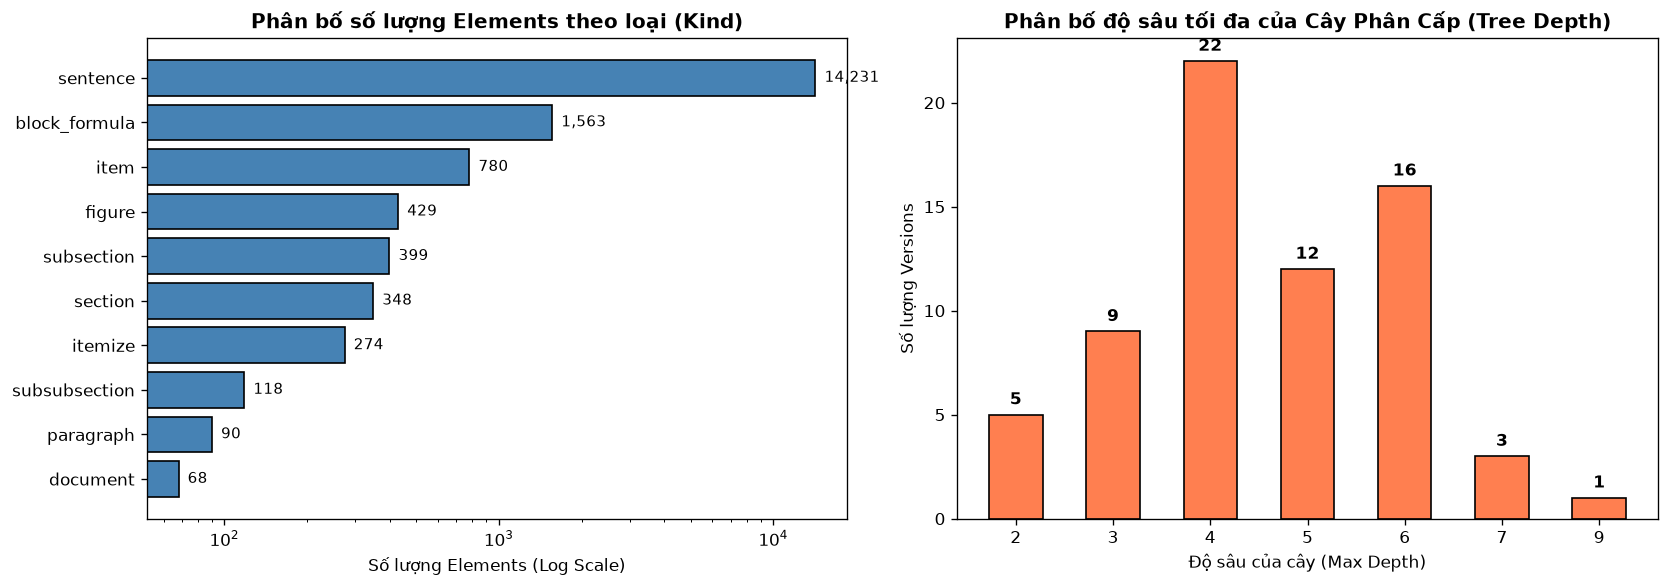

In [3]:
# Biểu đồ phân bố các loại phần tử (Element Kinds) và Độ sâu của Cây phân cấp (Tree Depth)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân bố Element Kinds
df_kinds = pd.DataFrame(
    sorted(kind_counts.items(), key=lambda x: x[1], reverse=True),
    columns=["Kind", "Count"]
)
axes[0].barh(df_kinds["Kind"][::-1], df_kinds["Count"][::-1], color="steelblue", edgecolor="black")
axes[0].set_title("Phân bố số lượng Elements theo loại (Kind)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Số lượng Elements (Log Scale)")
axes[0].set_xscale("log")
for i, v in enumerate(df_kinds["Count"][::-1]):
    axes[0].text(v * 1.08, i, f"{v:,}", va="center", fontsize=9)

# 2. Phân bố độ sâu của cây phân cấp (Hierarchy Tree Depth)
if depth_list:
    depth_series = pd.Series(depth_list).value_counts().sort_index()
    axes[1].bar(depth_series.index.astype(str), depth_series.values, color="coral", edgecolor="black", width=0.55)
    axes[1].set_title("Phân bố độ sâu tối đa của Cây Phân Cấp (Tree Depth)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Độ sâu của cây (Max Depth)")
    axes[1].set_ylabel("Số lượng Versions")
    for i, v in enumerate(depth_series.values):
        axes[1].text(i, v + 0.5, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

display(df_kinds)

In [4]:
# Minh họa cấu trúc Cây Phân Cấp (Hierarchy Tree) thực tế của bài báo 2510.10788 (Version 1)
sample_tree_path = source_dir / "2510.10788" / "v1" / "hierarchy_tree.json"
if sample_tree_path.is_file():
    tree_obj = json.loads(sample_tree_path.read_text(encoding="utf-8"))
    root = tree_obj["root"]
    print(f"Publication: {tree_obj['arxiv_id']} | Version: {tree_obj['version']} ({tree_obj['version_name']})")
    print(f"Tổng số Elements: {tree_obj['elements_count']} | Tổng số cạnh: {tree_obj['edges_count']}\n")
    print(f"[{root['kind'].upper()}] {root['element_id']}: {root['content']}")
    for sec in root["children"][:6]:
        print(f"  ├── [{sec['kind'].upper()}] {sec['element_id']}: {sec['content']} ({len(sec['children'])} phần tử con)")
        for child in sec["children"][:2]:
            preview = child["content"].replace("\n", " ")[:75]
            print(f"  │     └── ({child['kind']}) {child['element_id']}: {preview}...")

Publication: 2510.10788 | Version: 1 (v1)
Tổng số Elements: 238 | Tổng số cạnh: 237

[DOCUMENT] 2510.10788#root1: Version 1 root
  ├── [SECTION] 2510.10788#v1_h1: Abstract (9 phần tử con)
  │     └── (sentence) 2510.10788#v1_s1: Giant Goos-Hänchen shift is a promising effect for very highly sensitive se...
  │     └── (sentence) 2510.10788#v1_s2: For sensors working at the critical coupling regime, we provide here a comp...
  ├── [SECTION] 2510.10788#v1_h2: Introduction (24 phần tử con)
  │     └── (sentence) 2510.10788#v1_s10: The Goos-Hänchen (GH) effect is the lateral displacement of a reflected bea...
  │     └── (sentence) 2510.10788#v1_s11: This lateral displacement can be large in resonant photonic structures such...
  ├── [SECTION] 2510.10788#v1_h3: Formalism of sensor with Goos-Hänchen effect (51 phần tử con)
  │     └── (sentence) 2510.10788#v1_s34: When light is reflected by an interface at an angle of incidence $\theta_0$...
  │     └── (block_formula) 2510.10788#v1_eq1: \b